[![Ouvrir dans Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github.com/DEDJIABDOUL/omicaa-lab-MLforBiologistes/blob/main/notebooks/04_classification_biologique_pipeline.ipynb)

# Notebook 04 : classification supervisée, modèle de référence et pipelines

**Omicaa Lab | Machine Learning et Deep Learning pour les biologistes** | Auteur : DEDJI ABDOUL BATINOU

## Introduction scientifique

Prédire un diagnostic à partir de mesures revient à apprendre une fonction qui associe un vecteur de caractéristiques à une étiquette. La rigueur de la démarche tient moins à l'algorithme qu'au protocole : un modèle de référence, un prétraitement encapsulé, une évaluation sur des données jamais vues et des métriques qui répondent à la question biologique. Ce notebook compare quatre algorithmes sur le jeu Breast Cancer Wisconsin en gardant le jeu de test final strictement inutilisé.

## Objectifs techniques

1. Formaliser X, y et la tâche de classification binaire.
2. Construire des pipelines scikit-learn qui encapsulent prétraitement et modèle.
3. Comparer un modèle de référence, une régression logistique, un arbre de décision et une forêt aléatoire.
4. Calculer et interpréter accuracy, précision, rappel, F1, AUC, matrice de confusion et rapport de classification.
5. Distinguer paramètres appris et hyperparamètres.

## Prérequis

* Notebooks 02 et 03 terminés.

## Résultat attendu

Un tableau comparatif de modèles évalués sur un jeu de validation, une matrice de confusion interprétée biologiquement et la preuve que le jeu de test n'a pas été consulté.

## 1. Contrôle de l'environnement

In [1]:
import sys, platform, random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import json
from pathlib import Path
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python      :", platform.python_version())
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

Python      : 3.12.3
NumPy       : 2.4.4
pandas      : 3.0.2
Matplotlib  : 3.10.8
scikit-learn: 1.8.0


In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
ROUGE, CYAN, NOIR, GRIS = "#FF0000", "#0097B2", "#000000", "#8A8A8A"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 9.5, "font.size": 9.5})

## 2. Formalisation du problème

On note

$$X \in \mathbb{R}^{n \times p}, \qquad y \in \{0, 1\}^n$$

où $n$ est le nombre d'observations et $p$ le nombre de caractéristiques. Ici $n = 569$ et $p = 30$. L'élément $x_i \in \mathbb{R}^p$ est le vecteur de mesures de l'observation $i$ et $y_i$ son étiquette (1 pour maligne, 0 pour bénigne). Un modèle de classification est une fonction $f_\theta$ dont les **paramètres** $\theta$ sont estimés pendant l'entraînement pour que $f_\theta(x_i)$ approche $y_i$ sur les données d'entraînement, avec l'espoir que cette relation se **généralise** à de nouvelles observations.

On distingue :

* la **classification binaire** (deux classes, cas présent) et la classification multiclasse (plus de deux) ;
* la **régression**, où $y$ est une valeur continue (par exemple un niveau d'expression) ;
* l'**apprentissage non supervisé**, où il n'y a pas d'étiquette et où l'on cherche une structure (regroupements, projections).

La tâche est ici supervisée et le critère de performance est choisi **avant** de lancer les modèles : on privilégie la capacité à détecter les tumeurs malignes (rappel), sans perdre de vue la précision et l'AUC.

In [3]:
bunch = load_breast_cancer(as_frame=True)
X = bunch.data.copy()
y = (bunch.target == 0).astype(int).rename("maligne")        # 1 = maligne = classe positive

X_train, X_test_reserve, y_train, y_test_reserve = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

# Le jeu de test est renommé *_reserve pour signaler qu'il ne doit pas apparaître dans ce notebook.
# La validation se fait sur une partie de l'entraînement.
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEED)

print("entraînement (ajustement) :", X_tr.shape, "| validation :", X_val.shape, "| test réservé :", X_test_reserve.shape)
assert X.shape == (569, 30) and "maligne" not in X.columns
assert set(X_tr.index).isdisjoint(X_val.index) and set(X_tr.index).isdisjoint(X_test_reserve.index)
assert set(X_val.index).isdisjoint(X_test_reserve.index)
print("parts malignes :", round(y_tr.mean(), 3), round(y_val.mean(), 3), round(y_test_reserve.mean(), 3))

entraînement (ajustement) : (341, 30) | validation : (114, 30) | test réservé : (114, 30)
parts malignes : 0.372 0.377 0.368


## 3. Un modèle de référence avant tout

Un **modèle de référence** (baseline) fixe le niveau minimal à dépasser. `DummyClassifier` ignore les caractéristiques : avec la stratégie `most_frequent`, il prédit toujours la classe majoritaire. Si un modèle sophistiqué ne fait pas nettement mieux, il n'apporte rien.

In [4]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
pred = dummy.predict(X_val)
print("prédictions distinctes :", np.unique(pred))
print("accuracy :", round(accuracy_score(y_val, pred), 3), "| rappel :", recall_score(y_val, pred, zero_division=0))

prédictions distinctes : [0]
accuracy : 0.623 | rappel : 0.0


L'accuracy de ce modèle sans aucune intelligence est d'environ 0,62, mais son rappel est nul : il ne détecte **aucune** tumeur maligne. Cet exemple illustre pourquoi l'accuracy seule est un indicateur insuffisant lorsque les classes sont déséquilibrées ou que les erreurs n'ont pas le même coût.

## 4. Pipelines : encapsuler prétraitement et modèle

Un `Pipeline` enchaîne des transformations et un estimateur final sous une interface unique `fit` / `predict`. Lors de `fit`, chaque transformation est ajustée sur les données reçues, puis transmise à l'étape suivante. Lors de `predict`, les transformations ajustées sont **appliquées**, sans être réajustées. Intégré à une validation croisée (notebook 05), le pipeline est réajusté à chaque pli sur le seul sous-ensemble d'entraînement : la fuite d'information est exclue par construction.

`make_pipeline` est la version abrégée qui nomme automatiquement les étapes.

In [5]:
modeles = {
    "Référence (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": Pipeline([("scaler", StandardScaler()), ("modele", LogisticRegression(max_iter=1000))]),
    "Arbre de décision": make_pipeline(DecisionTreeClassifier(random_state=SEED)),
    "Forêt aléatoire": make_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED)),
}
print(modeles["Régression logistique"])

Pipeline(steps=[('scaler', StandardScaler()),
                ('modele', LogisticRegression(max_iter=1000))])


**Pourquoi un `StandardScaler` pour la régression logistique seulement.** La régression logistique est optimisée par un algorithme itératif et sa régularisation pénalise la taille des coefficients : des variables d'échelles très différentes rendent l'optimisation difficile et la pénalité inéquitable. Les arbres découpent selon des seuils sur une variable à la fois : un changement d'échelle monotone ne modifie pas les découpages, la mise à l'échelle est donc inutile.

## 5. Les algorithmes en bref

| Algorithme | Principe | Hyperparamètres principaux | Avantages | Limites |
|---|---|---|---|---|
| Régression logistique | combinaison linéaire des variables transformée en probabilité par la fonction sigmoïde | `C` (inverse de la régularisation) | rapide, coefficients interprétables, bonne référence | frontière linéaire, sensible aux variables corrélées |
| Arbre de décision | suite de questions binaires sur les variables qui partitionnent l'espace | `max_depth`, `min_samples_leaf` | lisible, aucune mise à l'échelle | surapprend facilement, instable |
| Forêt aléatoire | moyenne de nombreux arbres entraînés sur des échantillons bootstrap et des sous-ensembles de variables | `n_estimators`, `max_depth`, `max_features` | robuste, capture des non-linéarités | moins lisible, coût mémoire |

**Paramètres et hyperparamètres.** Les *paramètres* sont appris pendant l'entraînement (coefficients de la régression, seuils et variables des nœuds de l'arbre). Les *hyperparamètres* sont fixés avant l'entraînement et pilotent la complexité (`C`, `max_depth`, `n_estimators`). On ne peut pas les estimer sur les données d'entraînement seules sans surajustement : on les choisit par validation (notebook 05).

## 6. Entraînement et évaluation sur le jeu de validation

In [6]:
def evaluer(modele, X_a, y_a):
    """Retourne les cinq métriques d'un modèle déjà ajusté. La classe positive est 1 (maligne)."""
    pred = modele.predict(X_a)
    score = modele.predict_proba(X_a)[:, 1]
    return {"accuracy": accuracy_score(y_a, pred),
            "précision": precision_score(y_a, pred, zero_division=0),
            "rappel": recall_score(y_a, pred, zero_division=0),
            "F1": f1_score(y_a, pred, zero_division=0),
            "AUC": roc_auc_score(y_a, score)}

lignes = {}
for nom, m in modeles.items():
    m.fit(X_tr, y_tr)
    lignes[nom] = evaluer(m, X_val, y_val)
tableau = pd.DataFrame(lignes).T
print(tableau.round(3))

# Étape D : contrôle des sorties
for m in modeles.values():
    p = m.predict(X_val)
    assert p.shape == (len(X_val),) and set(np.unique(p)) <= {0, 1}
assert tableau.loc["Référence (classe majoritaire)", "AUC"] == 0.5

                                accuracy  précision  rappel     F1    AUC
Référence (classe majoritaire)     0.623      0.000   0.000  0.000  0.500
Régression logistique              0.974      0.955   0.977  0.966  0.996
Arbre de décision                  0.904      0.848   0.907  0.876  0.904
Forêt aléatoire                    0.974      0.976   0.953  0.965  0.992


**Lecture.** L'AUC du modèle de référence vaut exactement 0,5 : il ne discrimine pas. Les trois modèles apprenants dépassent ce plancher. La régression logistique et la forêt aléatoire sont presque indiscernables sur ce jeu de validation, alors que l'arbre non contraint est nettement en retrait (c'est le modèle qui a mémorisé l'entraînement). Avec 114 observations de validation, **une seule erreur modifie l'accuracy d'environ 0,9 point** : une différence d'un à deux points entre la régression logistique et la forêt ne permet pas de conclure. La validation croisée du notebook 05 quantifie cette variabilité.

**Définitions des métriques.** Avec VP, FP, VN, FN les effectifs de vrais positifs, faux positifs, vrais négatifs et faux négatifs :

$$\text{accuracy} = \frac{VP + VN}{n}, \quad \text{précision} = \frac{VP}{VP + FP}, \quad \text{rappel} = \frac{VP}{VP + FN}, \quad F_1 = \frac{2 \cdot \text{précision} \cdot \text{rappel}}{\text{précision} + \text{rappel}}$$

L'**AUC** (aire sous la courbe ROC) est la probabilité qu'une observation positive tirée au hasard reçoive un score plus élevé qu'une négative tirée au hasard. Elle mesure la **discrimination**, indépendamment du seuil de décision.

## 7. Matrice de confusion : un scénario biologique

La classe positive est *tumeur maligne*.

* **Vrai positif (VP)** : tumeur maligne prédite maligne. La patiente est orientée vers la prise en charge.
* **Faux négatif (FN)** : tumeur maligne prédite bénigne. Le diagnostic est manqué, le retard de traitement peut avoir des conséquences graves.
* **Faux positif (FP)** : tumeur bénigne prédite maligne. Examens complémentaires inutiles et anxiété, sans danger vital.
* **Vrai négatif (VN)** : tumeur bénigne prédite bénigne.

Les deux erreurs n'ont pas le même coût : dans un contexte de dépistage, on accepte plus volontiers des faux positifs que des faux négatifs. C'est pourquoi le **rappel** de la classe maligne est suivi avec attention.

VN=69  FP=2  FN=1  VP=42


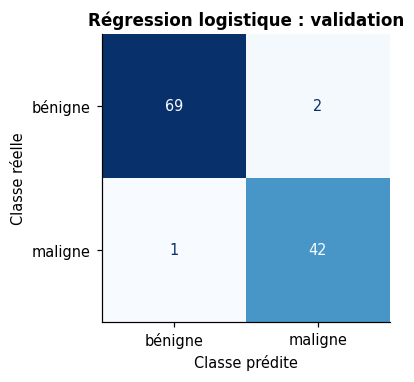

              precision    recall  f1-score   support

     bénigne      0.986     0.972     0.979        71
     maligne      0.955     0.977     0.966        43

    accuracy                          0.974       114
   macro avg      0.970     0.974     0.972       114
weighted avg      0.974     0.974     0.974       114



In [7]:
meilleur = modeles["Régression logistique"]
cm = confusion_matrix(y_val, meilleur.predict(X_val))
vn, fp, fn, vp = cm.ravel()
print(f"VN={vn}  FP={fp}  FN={fn}  VP={vp}")
assert vn + fp + fn + vp == len(y_val)

fig, ax = plt.subplots(figsize=(4.0, 3.4))
ConfusionMatrixDisplay.from_estimator(meilleur, X_val, y_val, display_labels=["bénigne", "maligne"],
                                      cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Régression logistique : validation")
ax.grid(False)
ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle")
fig.savefig(FIG / "fig_confusion_validation.png", dpi=170, bbox_inches="tight")
plt.show()
print(classification_report(y_val, meilleur.predict(X_val), target_names=["bénigne", "maligne"], digits=3))

Le `classification_report` calcule précision, rappel et F1 **pour chaque classe**, ainsi que leurs moyennes. La ligne *maligne* est celle qui répond à la question clinique. La colonne `support` donne le nombre d'observations réelles de chaque classe.

## 8. Paramètres appris, hyperparamètres et surapprentissage

In [8]:
lr = modeles["Régression logistique"].named_steps["modele"]
arbre = modeles["Arbre de décision"].steps[-1][1]
foret = modeles["Forêt aléatoire"].steps[-1][1]

print("Régression logistique : coefficients", lr.coef_.shape, "| intercept", lr.intercept_.round(3), "| hyperparamètre C =", lr.C)
print("Arbre : profondeur apprise =", arbre.get_depth(), "| nombre de feuilles =", arbre.get_n_leaves())
print("Forêt : nombre d'arbres =", len(foret.estimators_), "(hyperparamètre n_estimators =", foret.n_estimators, ")")

for nom in ["Arbre de décision", "Forêt aléatoire", "Régression logistique"]:
    a_train = accuracy_score(y_tr, modeles[nom].predict(X_tr))
    a_val = accuracy_score(y_val, modeles[nom].predict(X_val))
    print(f"{nom:24s} accuracy entraînement = {a_train:.3f} | validation = {a_val:.3f} | écart = {a_train - a_val:+.3f}")

Régression logistique : coefficients (1, 30) | intercept [-0.149] | hyperparamètre C = 1.0
Arbre : profondeur apprise = 6 | nombre de feuilles = 17
Forêt : nombre d'arbres = 300 (hyperparamètre n_estimators = 300 )
Arbre de décision        accuracy entraînement = 1.000 | validation = 0.904 | écart = +0.096


Forêt aléatoire          accuracy entraînement = 1.000 | validation = 0.974 | écart = +0.026
Régression logistique    accuracy entraînement = 0.988 | validation = 0.974 | écart = +0.015


L'arbre non contraint atteint une accuracy de 1,000 sur l'entraînement : il a mémorisé les données. L'écart avec la validation mesure le **surapprentissage**. Limiter la profondeur est une forme de **régularisation** : on bride la complexité pour améliorer la généralisation. On l'illustre ci-dessous.

In [9]:
profondeurs = [1, 2, 3, 4, 5, 8, None]
rows = []
for d in profondeurs:
    t = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_tr, y_tr)
    rows.append({"max_depth": "aucune" if d is None else d,
                 "train": accuracy_score(y_tr, t.predict(X_tr)), "validation": accuracy_score(y_val, t.predict(X_val))})
profil = pd.DataFrame(rows)
print(profil.round(3).to_string(index=False))

max_depth  train  validation
        1  0.930       0.930
        2  0.947       0.886
        3  0.982       0.921
        4  0.991       0.895
        5  0.997       0.930
        8  1.000       0.904
   aucune  1.000       0.904


**Lire un arbre.** Un arbre de profondeur 3 est entièrement lisible : chaque chemin de la racine à une feuille est une règle.

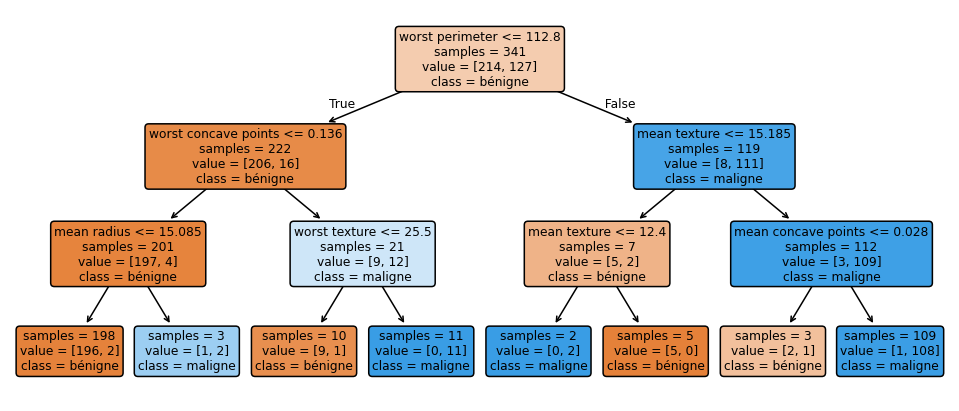

In [10]:
petit = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_tr, y_tr)
fig, ax = plt.subplots(figsize=(11, 4.6))
plot_tree(petit, feature_names=list(X.columns), class_names=["bénigne", "maligne"], filled=True,
          rounded=True, impurity=False, proportion=False, fontsize=8, ax=ax)
fig.savefig(FIG / "fig_arbre.png", dpi=170, bbox_inches="tight")
plt.show()

## 9. Importance des caractéristiques : une lecture prudente

La forêt aléatoire fournit `feature_importances_` (réduction moyenne d'impureté attribuée à chaque variable). Ce n'est pas une mesure d'effet biologique. Lorsque des variables sont corrélées (rayon, périmètre et aire), l'importance se **répartit** entre elles : aucune ne ressort autant qu'elle le ferait seule. L'importance est une propriété du modèle ajusté, pas du phénomène.

worst perimeter         0.148
worst area              0.133
mean concave points     0.107
worst concave points    0.107
mean radius             0.068
worst radius            0.066
mean perimeter          0.051
mean concavity          0.043
dtype: float64


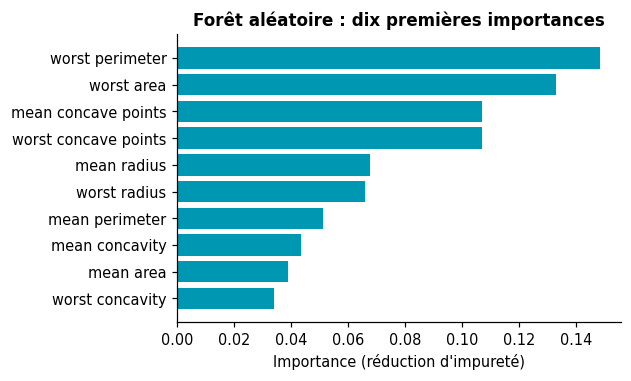

In [11]:
imp = pd.Series(foret.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(8).round(3))
fig, ax = plt.subplots(figsize=(5.2, 3.4))
top = imp.head(10)[::-1]
ax.barh(top.index, top.values, color=CYAN)
ax.set_xlabel("Importance (réduction d'impureté)")
ax.set_title("Forêt aléatoire : dix premières importances")
fig.savefig(FIG / "fig_importances.png", dpi=170, bbox_inches="tight")
plt.show()

## 10. Contrôle d'intégrité : le jeu de test est resté intact

In [12]:
# Aucun des modèles n'a été ajusté ni évalué sur le jeu réservé.
# On vérifie les tailles et on consigne les résultats de validation.
assert len(X_test_reserve) == 114
journal = {"notebook": "04", "graine": SEED, "sklearn": sklearn.__version__,
           "n_ajustement": len(X_tr), "n_validation": len(X_val), "n_test_reserve": len(X_test_reserve),
           "validation": {k: {m: round(float(v), 4) for m, v in r.items()} for k, r in lignes.items()},
           "matrice_confusion_logreg": {"VN": int(vn), "FP": int(fp), "FN": int(fn), "VP": int(vp)}}
(RES / "nb04.json").write_text(json.dumps(journal, ensure_ascii=False, indent=2))
print("Journal enregistré dans", RES / "nb04.json")

Journal enregistré dans results/nb04.json


## 11. Exercices progressifs

**Exercice 1.** Entraînez une régression logistique avec `C=0.01` (forte régularisation) et comparez son rappel de validation à celui de `C=1`. Quel effet a la régularisation ?

*Solution de l'exercice 1*

In [13]:
for c in [0.01, 1.0]:
    p = make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=1000)).fit(X_tr, y_tr)
    print(f"C = {c:<5} rappel validation = {recall_score(y_val, p.predict(X_val)):.3f} | accuracy = {accuracy_score(y_val, p.predict(X_val)):.3f}")

C = 0.01  rappel validation = 0.907 | accuracy = 0.965
C = 1.0   rappel validation = 0.977 | accuracy = 0.974


**Exercice 2.** Modifiez `random_state` de la forêt (par exemple 0, 1, 2). Les scores changent-ils ? Que cela implique-t-il pour la comparaison de deux algorithmes ?

*Solution de l'exercice 2*

In [14]:
for graine in [0, 1, 2]:
    f = RandomForestClassifier(n_estimators=300, random_state=graine).fit(X_tr, y_tr)
    print(graine, round(accuracy_score(y_val, f.predict(X_val)), 3), round(roc_auc_score(y_val, f.predict_proba(X_val)[:, 1]), 4))

0 0.974 0.9918


1 0.974 0.9915


2 0.974 0.991


**Exercice 3.** Calculez le rappel à la main à partir de la matrice de confusion de la régression logistique et vérifiez qu'il coïncide avec `recall_score`.

*Solution de l'exercice 3*

In [15]:
rappel_main = vp / (vp + fn)
assert abs(rappel_main - recall_score(y_val, meilleur.predict(X_val))) < 1e-12
print(round(rappel_main, 4))

0.9767


**Exercice 4.** Remplacez `LogisticRegression` par un pipeline sans `StandardScaler`. Observe-t-on un avertissement de convergence ? Que conclure ?

*Solution de l'exercice 4*

In [16]:
import warnings
with warnings.catch_warnings(record=True) as avertissements:
    warnings.simplefilter("always")
    sans_echelle = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
print("avertissements :", len(avertissements), [str(a.category.__name__) for a in avertissements][:2])
print("accuracy validation sans mise à l'échelle :", round(accuracy_score(y_val, sans_echelle.predict(X_val)), 3))

avertissements : 1 ['ConvergenceWarning']
accuracy validation sans mise à l'échelle : 0.974


## 12. Synthèse des compétences acquises

* Formaliser un problème supervisé par $X$, $y$, une tâche et un critère.
* Établir un modèle de référence et mesurer l'apport réel de modèles plus complexes.
* Encapsuler prétraitement et modèle dans un `Pipeline`.
* Interpréter accuracy, précision, rappel, F1, AUC et matrice de confusion avec un scénario biologique.
* Distinguer paramètres et hyperparamètres, repérer le surapprentissage, lire l'importance avec prudence.

**Suite.** Le notebook 05 remplace le jeu de validation unique, trop bruité, par la validation croisée, optimise les hyperparamètres sans toucher au test, puis réalise l'évaluation finale.